# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed.zarr")

In [3]:
# Define the saving path for the figures
saving_path = '/media/sergio/Meninges/troutpy/figures'

# 1. Additional unimodal plots

In [27]:
transcripts=sdata['transcripts'].compute()
transcripts["control_probe"] = transcripts["gene"].str.startswith(("Neg", "BLANK","Unass"))
sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)

In [28]:
troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene",percentile_threshold=99)
troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")

In [32]:
troutpy.pp.filter_urna(sdata,min_logfoldratio_over_noise=0,gene_key="gene")

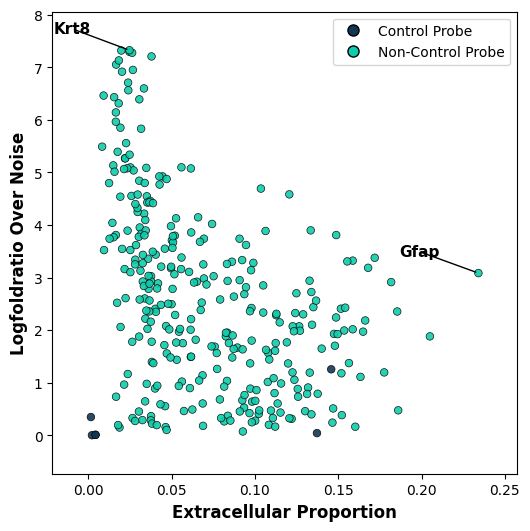

In [45]:
troutpy.pl.metric_scatter(sdata,x='extracellular_proportion',y='logfoldratio_over_noise',label_top_n_x=1,label_top_n_y=1,size=30,save=True,
                         figures_path=saving_path)

No transformation matrix found. Proceeding without transformation.


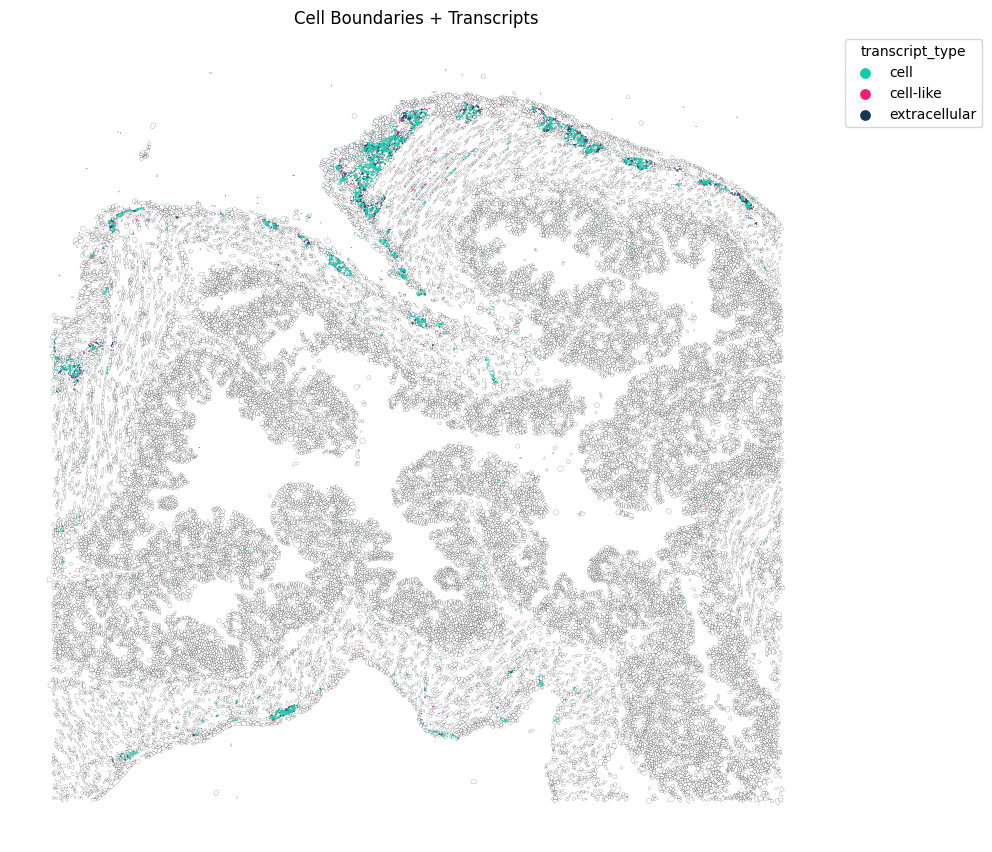

In [41]:
fig=troutpy.pl.spatial_transcripts(sdata, gene_list=['Gfap'],scatter_size=0.6,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_gfap.pdf'))

No transformation matrix found. Proceeding without transformation.


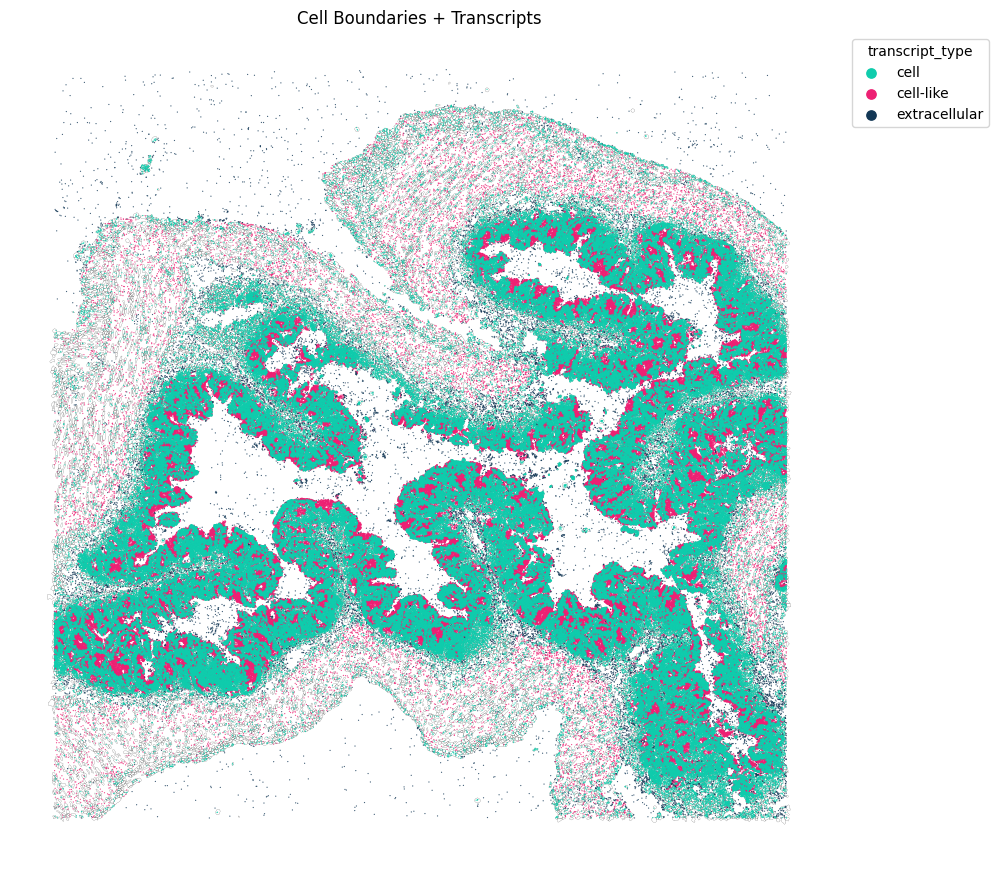

In [46]:
troutpy.pl.spatial_transcripts(sdata, gene_list=['Krt8'],scatter_size=0.8,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_krt8.pdf'))

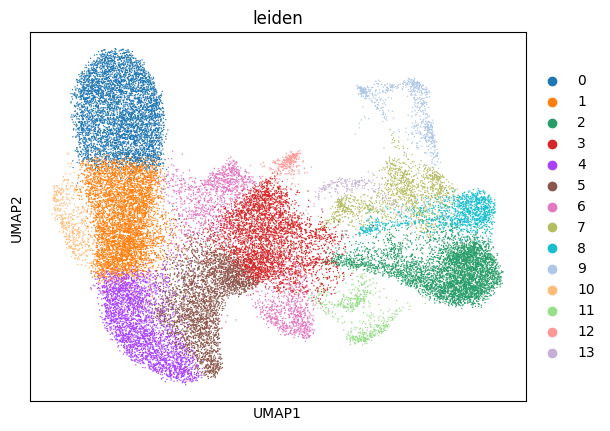

In [52]:
sc.pl.umap(sdata['table'],color='leiden')

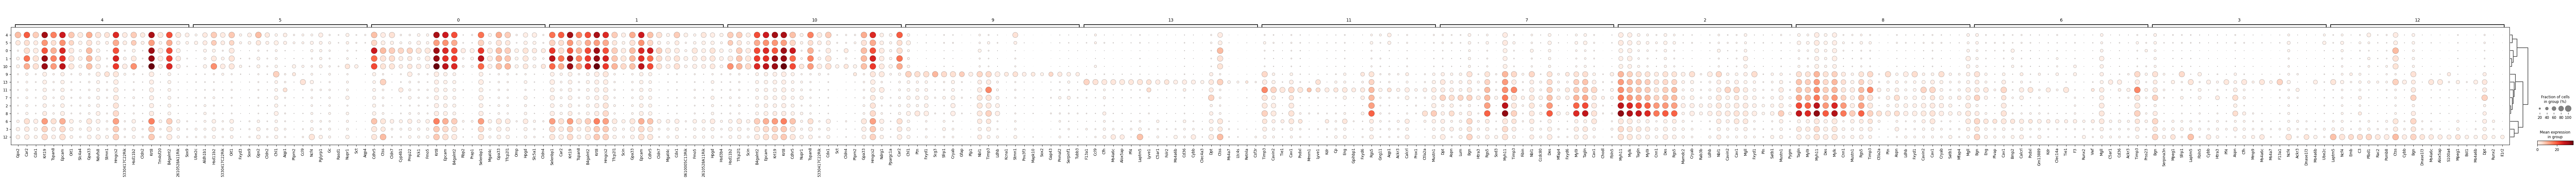

In [71]:
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=20)

In [95]:
glial_markers=['Gfap','Plp1','Sox2']

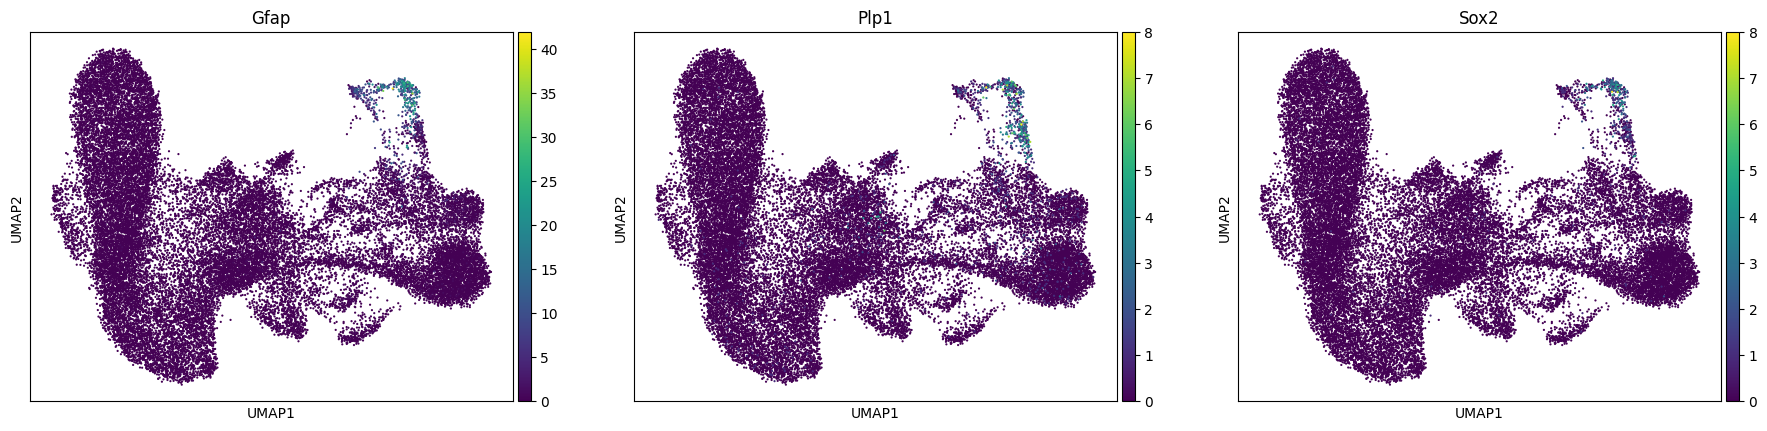

In [96]:
sc.pl.umap(sdata['table'],color=glial_markers,s=10)

In [97]:
urna_metadata=sdata['xrna_metadata'].var
glia_metadata=urna_metadata.loc[urna_metadata.index.isin(glial_markers),:]

In [108]:
glia_metadata

,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular
Plp1,0.070018,0.0,0.000013,NaN,0.170153,5.728539e-195,0.095238,2448,1.669195,False,0.0,0.910539,0.089461,-1.120303
Gfap,0.437957,0.0,0.000013,NaN,0.338139,0.000000e+00,0.579268,10093,3.085766,False,0.0,0.765877,0.234123,-2.255363
Sox2,0.060590,0.0,0.000013,NaN,0.201781,5.679661e-275,0.084211,1090,0.860101,False,0.0,0.899083,0.100917,-1.253467


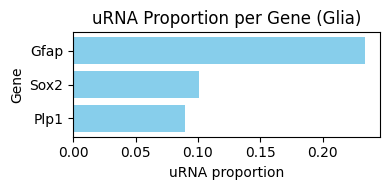

In [104]:
import pandas as pd
import matplotlib.pyplot as plt

# Sort the DataFrame by 'extracellular_proportion' in descending order
sorted_df = glia_metadata.sort_values('extracellular_proportion', ascending=True)

# Create the bar plot
plt.figure(figsize=(4, 2))
plt.barh(sorted_df.index, sorted_df['extracellular_proportion'], color='skyblue')

# Rotate x-axis labels for better readability
#plt.xticks(rotation=90)

# Add labels and title
plt.ylabel('Gene')
plt.xlabel('uRNA proportion')
plt.title('uRNA Proportion per Gene (Glia)')

# Tight layout for better spacing
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'glial_markers_proportion_bar.pdf'))
plt.show()



No transformation matrix found. Proceeding without transformation.


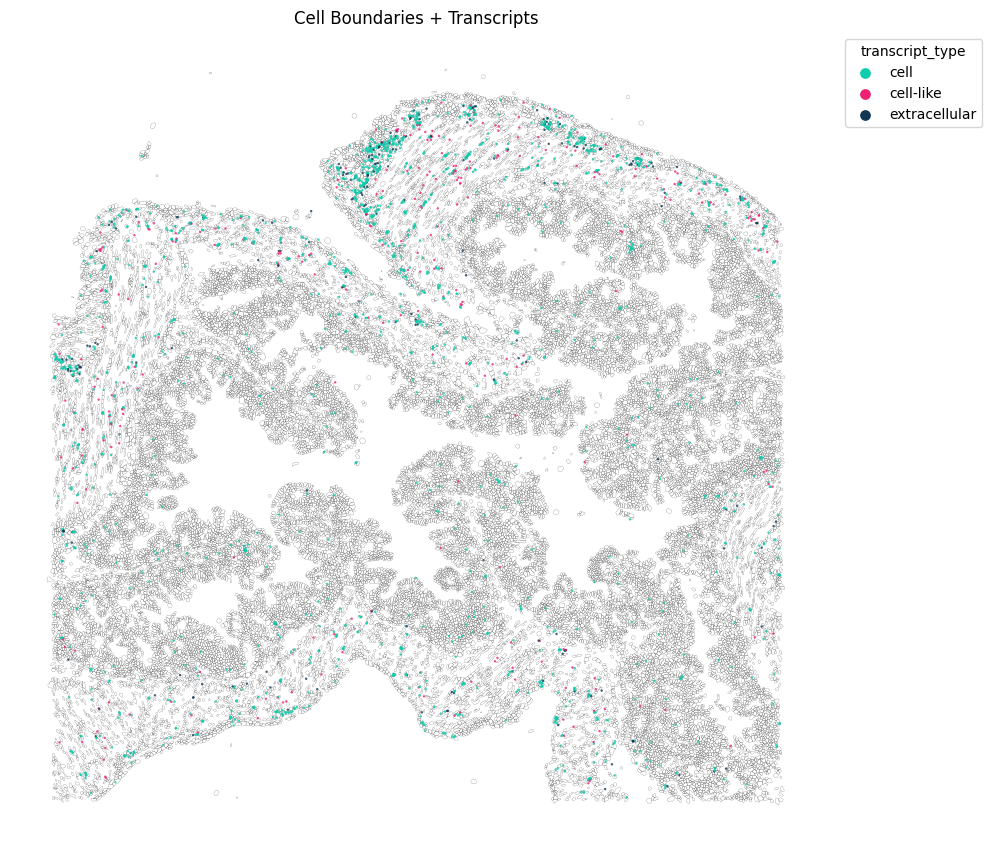

In [103]:
fig=troutpy.pl.spatial_transcripts(sdata, gene_list=['Plp1'],scatter_size=3,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_plp1.pdf'))

No transformation matrix found. Proceeding without transformation.


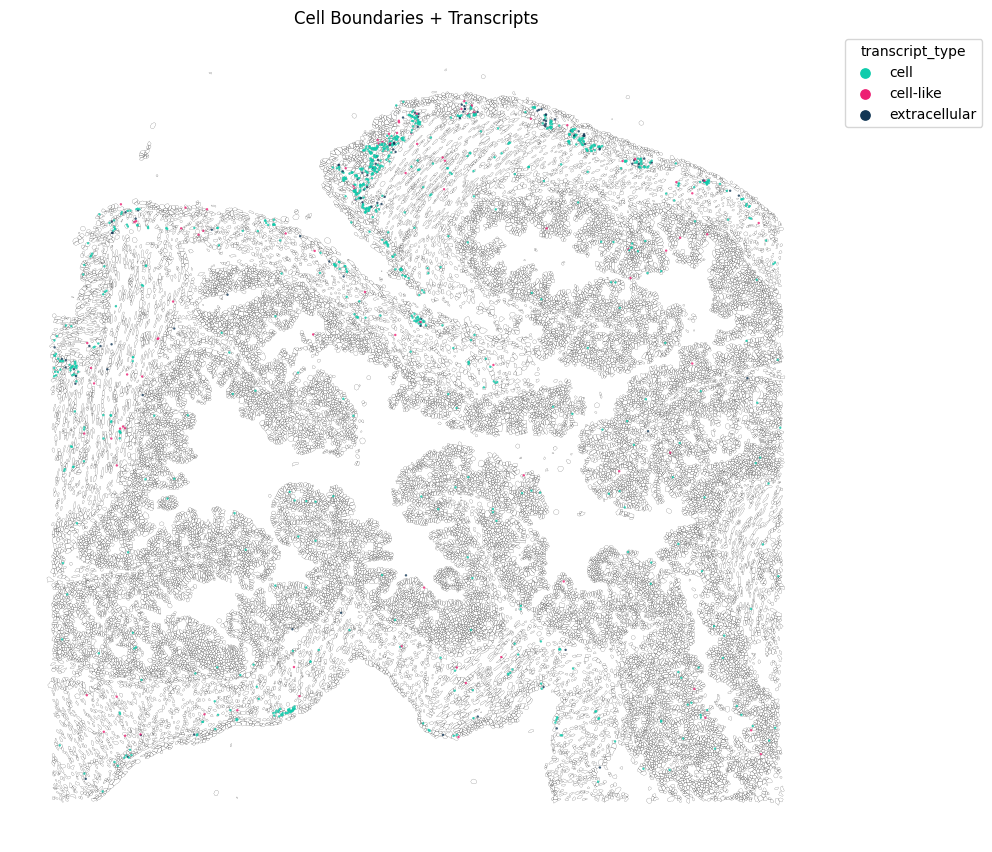

In [102]:
fig=troutpy.pl.spatial_transcripts(sdata, gene_list=['Sox2'],scatter_size=3,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_sox2.pdf'))

<Axes: xlabel='logfoldratio_over_noise', ylabel='extracellular_proportion'>

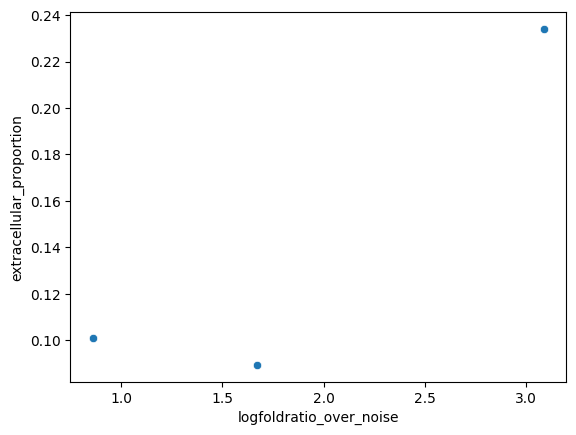

In [99]:
sns.scatterplot(data=glia_metadata,x='logfoldratio_over_noise',y='extracellular_proportion')

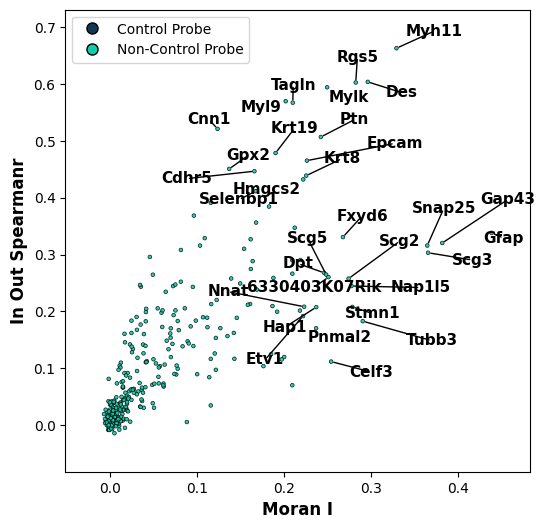

In [105]:
troutpy.pl.metric_scatter(sdata,x='moran_I',y='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=25,label_top_n_y=15,size=7)

No transformation matrix found. Proceeding without transformation.


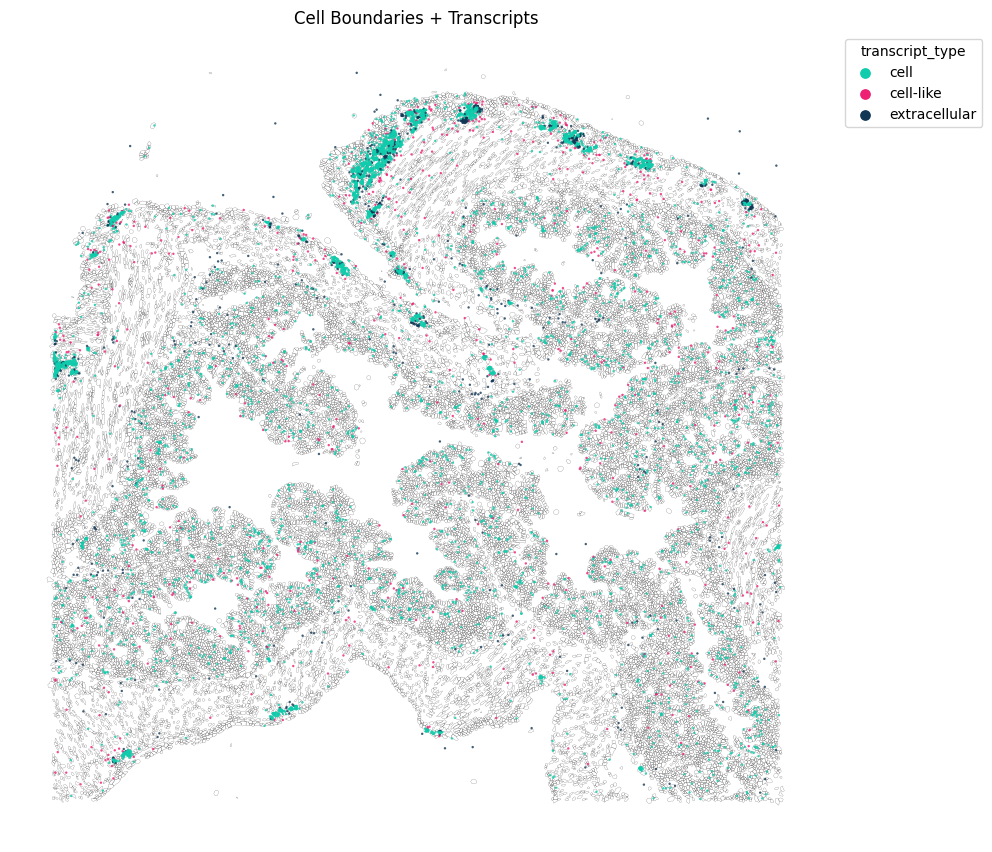

In [107]:
fig=troutpy.pl.spatial_transcripts(sdata, gene_list=['Celf3'],scatter_size=3,figsize=(10,10),boundary_linewidth=0.1)
#plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_celf3.pdf'))